# IMDB Sentiment Analysis — 04 · Model Training & Evaluation

**Reconess AI Internship · Phase II · Practical project notebook**

### Learning goals

- Train baseline text classifiers with **Logistic Regression** and **Linear SVM**.
- Compare **TF-IDF** (term weights) with **Bag of Words / BoW** (term counts).
- Measure **Accuracy, Precision, Recall, and F1-Score** on the **same validation set**.
- Inspect a **Confusion Matrix** for the best-performing current model.

> **Evaluation rule:** `test.csv` is held out for the final project evaluation. The models in this notebook are compared using only a validation split of `train.csv`.

**Data flow:** `train.csv` → Train/Validation split → Pipeline (vectorizer + classifier) → Validation predictions → Metrics. The vectorizer is fitted using **training data only**.

## 1 · Load training data and create a validation split

**Why?** We need a fair way to compare model settings **before** touching the final Test Set.

`train.csv` was exported after text cleaning and duplicate removal. Its `review` column contains preprocessed movie reviews, while `sentiment` contains the `positive` and `negative` labels.

We split this file again: **80% training / 20% validation**. This corresponds to approximately **64% training, 16% validation, and 20% final test** of the original project split. The final-test portion remains in `test.csv` and is **not loaded in this notebook**.

The original notebook uses an absolute Windows file path; update that path if you move the project to a different folder or computer.

In [56]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the cleaned reviews exported by the preprocessing notebook.
# Note: this is train.csv, NOT the untouched final test.csv.
train_df = pd.read_csv("D:/imdb-sentiment-analysis/data/train.csv")

# X = cleaned review texts (features); y = sentiment labels (target).
X = train_df["review"]
y = train_df["sentiment"]

# Set aside 20% of train.csv for model comparison (validation).
# stratify=y preserves the class proportions in both subsets.
# random_state makes this split reproducible.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)


(31728,) (7932,) (31728,) (7932,)


**Expected from the saved run:** `X_train = (31728,)` and `X_val = (7932,)`, with matching `y_train` and `y_val` lengths. One element of `X` is a review text, so these are 1D Series shapes, not feature matrices yet.

`stratify=y` preserves the positive/negative class balance, while `random_state=42` makes this particular split reproducible.

## 2 · Baseline A: Logistic Regression + TF-IDF

- **TF-IDF:** represents documents with weighted word features; common words tend to receive lower inverse-document-frequency weight.
- **Logistic Regression:** learns a decision boundary for classifying a review as `positive` or `negative`.
- **Pipeline:** performs the vectorizer's `fit_transform` on `X_train` and then trains the classifier. During prediction, it only **transforms** validation text — it does **not refit** the vectorizer.

Using `Pipeline` avoids accidentally building the TF-IDF vocabulary from validation reviews (**data leakage**). The variable `pipeline_ir` is the name used in your original notebook for the Logistic Regression pipeline.

In [57]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Pipeline: learn TF-IDF only from X_train, then train Logistic Regression.
# max_features=5000 caps the number of vocabulary features.
# max_iter=1000 gives the optimizer up to 1000 iterations to converge.
pipeline_ir = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

pipeline_ir.fit(X_train, y_train)
print("end")


end


### 2.1 · Evaluate Logistic Regression on validation data

**Metric quick reference** (with `positive` treated as the positive class):

| Metric | What it tells us |
|---|---|
| **Accuracy** | Fraction of all reviews classified correctly |
| **Precision** | Of reviews predicted positive, how many are truly positive? |
| **Recall** | Of truly positive reviews, how many did we detect? |
| **F1-Score** | Harmonic mean of Precision and Recall |

`pos_label="positive"` matters because the labels are strings, not numeric `0` and `1`. This evaluation is on **X_val**, not on the final test file.

In [58]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

# Predict on validation data only; no fitting happens on X_val.
pipeline_prediction_ir = pipeline_ir.predict(X_val)

# These are binary sentiment labels stored as strings.
# For Precision, Recall, and F1, 'positive' is the positive class.
f1 = f1_score(y_val, pipeline_prediction_ir, pos_label="positive")
accuracy = accuracy_score(y_val, pipeline_prediction_ir)
precision = precision_score(y_val, pipeline_prediction_ir, pos_label="positive")
recall = recall_score(y_val, pipeline_prediction_ir, pos_label="positive")

print("F1 Score:", f1)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)


F1 Score: 0.8851309031692346
Accuracy: 0.8843923348461926
Precision: 0.882808595702149
Recall: 0.8874654609394624


## 3 · Baseline B: Linear SVM + TF-IDF

This experiment keeps the same **TF-IDF settings**, **training subset**, and **validation subset**. Only the classifier changes to `LinearSVC`, a linear support vector classifier that works well with sparse high-dimensional text data.

This is a **controlled comparison**: it helps us see whether switching classifiers helps without changing several factors at once.

In [59]:
from sklearn.svm import LinearSVC

# Keep TF-IDF and the split the same, changing only the classifier.
# LinearSVC is a linear SVM suited to high-dimensional sparse text features.
pipeline_svc = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("classifier", LinearSVC(random_state=42)),
])

pipeline_svc.fit(X_train, y_train)
print("end")


end


### 3.1 · Evaluate Linear SVM + TF-IDF

We compute the **same four metrics** on the **same validation reviews** so that the comparison with Logistic Regression is meaningful.

In [60]:
# Linear SVM + TF-IDF predictions on the SAME validation set.
pipeline_prediction = pipeline_svc.predict(X_val)

# Dedicated suffixes keep the SVM metrics separate from the LR metrics.
# (_smv is the original variable name retained from the working notebook.)
f1_smv = f1_score(y_val, pipeline_prediction, pos_label="positive")
accuracy_smv = accuracy_score(y_val, pipeline_prediction)
precision_smv = precision_score(y_val, pipeline_prediction, pos_label="positive")
recall_smv = recall_score(y_val, pipeline_prediction, pos_label="positive")

print("F1 Score:", f1_smv)
print("Accuracy:", accuracy_smv)
print("Precision:", precision_smv)
print("Recall:", recall_smv)


F1 Score: 0.877197388247112
Accuracy: 0.8767019667170953
Precision: 0.8769771528998243
Recall: 0.8774177342376287


## 4 · Baseline C: Logistic Regression + Bag of Words

`CountVectorizer` creates **word-count features**, unlike TF-IDF, which assigns weighted values. We again use up to **5,000 features**, the same Logistic Regression settings, and the same split.

Here we test the question: *Does TF-IDF outperform plain word counts for this dataset and classifier?*

In [61]:
# Now change text representation: BoW counts instead of TF-IDF weights.
# We keep Logistic Regression settings and the train/validation split fixed.
pipeline_ir_bow = Pipeline([
    ("bow", CountVectorizer(max_features=5000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

pipeline_ir_bow.fit(X_train, y_train)
print("end")


end


### 4.1 · Evaluate Logistic Regression + BoW

The printed scores in this cell belong to **Logistic Regression + BoW**. The variable names `f1`, `accuracy`, `precision`, and `recall` are reused in the original notebook; the **model predictions and printed outputs** still correspond to this specific run.

In [62]:
# Predict with Logistic Regression + BoW.
pipeline_prediction = pipeline_ir_bow.predict(X_val)

# These generic metric names are reused in the original notebook.
# The printed scores below belong specifically to Logistic Regression + BoW.
f1 = f1_score(y_val, pipeline_prediction, pos_label="positive")
accuracy = accuracy_score(y_val, pipeline_prediction)
precision = precision_score(y_val, pipeline_prediction, pos_label="positive")
recall = recall_score(y_val, pipeline_prediction, pos_label="positive")

print("F1 Score:", f1)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)


F1 Score: 0.86062893081761
Accuracy: 0.8603126575895108
Precision: 0.8619299571680524
Recall: 0.859331826174328


## 5 · Baseline D: Linear SVM + Bag of Words

The fourth combination uses **CountVectorizer + LinearSVC**. At this point we have a 2 × 2 comparison: two vectorization methods and two classifiers.

In [63]:
# Fourth baseline: Linear SVM with Bag of Words.
# All four experiments use the same X_train / X_val for comparison.
pipeline_svc_bow = Pipeline([
    ("bow", CountVectorizer(max_features=5000)),
    ("classifier", LinearSVC(random_state=42)),
])

pipeline_svc_bow.fit(X_train, y_train)
print("end")


end


### 5.1 · Evaluate Linear SVM + BoW

Same validation set, same metrics, same positive class. This completes the four baseline experiments.

In [64]:
# Predict and evaluate Linear SVM + BoW.
pipeline_prediction = pipeline_svc_bow.predict(X_val)

f1 = f1_score(y_val, pipeline_prediction, pos_label="positive")
accuracy = accuracy_score(y_val, pipeline_prediction)
precision = precision_score(y_val, pipeline_prediction, pos_label="positive")
recall = recall_score(y_val, pipeline_prediction, pos_label="positive")

print("F1 Score:", f1)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)


F1 Score: 0.8425832492431887
Accuracy: 0.8426626323751891
Precision: 0.8462123131492273
Recall: 0.8389851796031148


## 6 · Baseline comparison — results from the saved run

These numbers summarize the results already printed by the cells above. They are a **snapshot**, not a table that auto-updates if you retrain or change parameters.

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| **Logistic Regression + TF-IDF** | **88.44%** | **88.28%** | **88.75%** | **88.51%** |
| Linear SVM + TF-IDF | 87.67% | 87.70% | 87.74% | 87.72% |
| Logistic Regression + BoW | 86.03% | 86.19% | 85.93% | 86.06% |
| Linear SVM + BoW | 84.27% | 84.62% | 83.90% | 84.26% |

**What we learned:**

1. In **these experiments**, TF-IDF performed better than BoW for both classifiers.
2. Logistic Regression performed better than Linear SVM at the **current/default classifier settings**.
3. **Logistic Regression + TF-IDF** is the **best validation baseline so far**, with Accuracy ≈ **88.44%** and F1 ≈ **88.51%**.
4. These comparisons **do not prove** the same model will always be best; hyperparameter tuning may change the ranking.

> **Do not choose models based on the final test set.** Use the validation set or cross-validation for selection. Keep `test.csv` untouched until final evaluation.

## 7 · Confusion Matrix — Logistic Regression + TF-IDF

The matrix breaks predictions into four cases. Here **rows are true labels** and **columns are predicted labels**. With `positive` as the positive class:

| | Predicted negative | Predicted positive |
|---|---:|---:|
| **True negative** | **TN = 3,482** | **FP = 469** |
| **True positive** | **FN = 448** | **TP = 3,533** |

- **Correct:** TN + TP = **7,015** reviews.
- **Incorrect:** FP + FN = **917** reviews.
- **Accuracy check:** `7015 / 7932 ≈ 88.44%`.

We plot the stored predictions from **`pipeline_ir`**, not the generic `pipeline_prediction` variable, which is reused by later experiments.

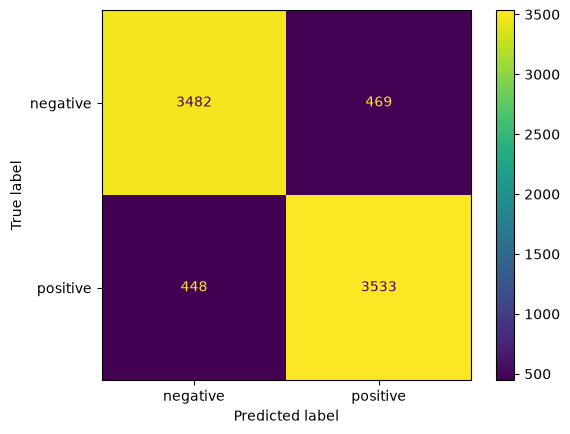

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

# Show the confusion matrix for the BEST current baseline (LR + TF-IDF).
# 'pipeline_prediction_ir' was stored earlier so it is not overwritten
# by the predictions for other model experiments.
# from_predictions() already creates the plot; no extra .plot() is needed.
disp = ConfusionMatrixDisplay.from_predictions(y_val, pipeline_prediction_ir)


In [68]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

scorer = make_scorer(f1_score, pos_label="positive")
grid_parameters = {
    "tfidf__max_features": [5000, 10000, 20000,500000,1000000],
    "classifier__C": [0.1, 1, 10,100,200],
}

grid_search = GridSearchCV(
    pipeline_ir,
    grid_parameters,
    scoring=scorer,
    cv=3
)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)


{'classifier__C': 10, 'tfidf__max_features': 500000}
0.8952395232712931


In [67]:
best_model = grid_search.best_estimator_

prediction=best_model.predict(X_val)

f1 = f1_score(y_val, prediction, pos_label="positive")
accuracy = accuracy_score(y_val, prediction)
precision = precision_score(y_val, prediction, pos_label="positive")
recall = recall_score(y_val, prediction, pos_label="positive")

print("F1 Score:", f1)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)


F1 Score: 0.8904212637913741
Accuracy: 0.8898134140191629
Precision: 0.8888610763454318
Recall: 0.8919869379552876


In [69]:
import joblib
joblib.dump(best_model, "D:/imdb-sentiment-analysis/models/lr_tfidf_tuned.joblib")

['D:/imdb-sentiment-analysis/models/lr_tfidf_tuned.joblib']